In [21]:
import numpy as np
import mne
import multi.modules.evaluatefold as ef
from mne.decoding import XdawnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
from sklearn.base import clone
import matplotlib.pyplot as plt

func_map = {
    "decision_function": lambda clf, X: clf.decision_function(X),
    "predict_proba": lambda clf, X: clf.predict_proba(X)
}

def split_fold(X_, y_, n_splits=10):
    skf = StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=42)
    out_data = []
    for train_idx, test_idx in skf.split(X_, y_):
        X_train, y_train, X_test, y_test = [], [], [], []
        X_testjj =  np.concatenate([[X_[test_idx, :, 750+(j+t)*25:900+(j+t)*25] for t in range(10)] for j in range(16) ], axis=1)
        y_testjj = np.tile(y_[test_idx], 16)
        for jj in range(25):
            X_train.append(X_[train_idx,:,750+jj*25:900+jj*25])
            y_train.append(y_[train_idx])
            X_test.append(X_testjj)
            y_test.append(y_testjj)
        fold_data = [np.array(X_train), np.array(y_train),X_test,y_test]
        out_data.append(fold_data)
    return out_data

def train_test_flod(clf, split_folds):
    cm_all = []
    for X_train, y_train, X_test, y_test in split_folds:
        cm_tt = []
        for jj in range(25):
            clf_fold = clone(clf)
            clf_fold.fit(X_train[jj], y_train[jj])
            sall = []
            for tt in range(10):
                score_func1 = "decision_function" if hasattr(clf_fold, "decision_function") else "predict_proba"
                s1 = func_map[score_func1](clf_fold, X_test[jj][tt])
                sall.append(s1)
            score_m = np.mean(np.array(sall), axis=0) 
            y_pred = (score_m >= 0).astype(int) if score_m.ndim == 1 else np.argmax(score_m, axis=1)
            cm = confusion_matrix(y_test[jj], y_pred, normalize='true')
            cm_tt.append(cm)
        cm_all.append(cm_tt)
    return np.array(cm_all)

def evaluate_all_samples(data, clf2, clf4, n_splits=10):
    cm_2, cm_4 = [], []
    for X2, y2, X4, y4 in data:
        split_folds2 = split_fold(X2, y2, n_splits=n_splits)
        cm2 = train_test_flod(clf2, split_folds2)
        split_folds4 = split_fold(X4, y4, n_splits=n_splits)
        cm4 = train_test_flod(clf4, split_folds4)
        cm_2.append(cm2)
        cm_4.append(cm4)
    return np.array(cm_2), np.array(cm_4)

def evaluate_cross_subject(data, clf2, clf4):
    cm_2, cm_4 = [], []
    for ss in range(20):
        # prepare training and testing data
        train = [data[i] for i in range(len(data)) if i != ss]
        X_train2 = np.concatenate([d[0] for d in train])
        y_train2 = np.concatenate([d[1] for d in train])
        X_train4 = np.concatenate([d[2] for d in train])
        y_train4 = np.concatenate([d[3] for d in train])
        
        X_train2 = [X_train2[:, :, 750+j*25:900+j*25] for j in range(25)]
        X_train4 = [X_train4[:, :, 750+j*25:900+j*25] for j in range(25)]
        # prepare testing data for imagery 
        X_test2, y_test2, X_test4, y_test4 = data[ss]
        X_test2  = np.concatenate([[X_test2[:, :, 750+(j+t)*25:900+(j+t)*25] for t in range(10)] for j in range(16) ], axis=1)
        X_test4  = np.concatenate([[X_test4[:, :, 750+(j+t)*25:900+(j+t)*25] for t in range(10)] for j in range(16) ], axis=1)
        y_test2 = np.tile(y_test2, 16)
        y_test4 = np.tile(y_test4, 16)
        # train and test
        clf2_clone = clone(clf2)
        clf4_clone = clone(clf4)
        cm_2tt, cm_4tt = [], []
        for jj in range(25):
            clf2_clone = clone(clf2)
            clf4_clone = clone(clf4)
            
            clf2_clone.fit(X_train2[jj], y_train2)
            sall = []
            for tt in range(10):
                score_func1 = "decision_function" if hasattr(clf2_clone, "decision_function") else "predict_proba"
                s1 = func_map[score_func1](clf2_clone, X_test2[tt])
                sall.append(s1)
            score_m = np.mean(np.array(sall), axis=0) 
            y_pred2 = (score_m >= 0).astype(int) if score_m.ndim == 1 else np.argmax(score_m, axis=1)
            cm2ss = confusion_matrix(y_test2, y_pred2, normalize='true')
            cm_2tt.append(cm2ss)
        
            clf4_clone.fit(X_train4[jj], y_train4)
            sall = []
            for tt in range(10):
                score_func1 = "decision_function" if hasattr(clf4_clone, "decision_function") else "predict_proba"
                s1 = func_map[score_func1](clf4_clone, X_test4[tt])
                sall.append(s1)
            score_m = np.mean(np.array(sall), axis=0) 
            y_pred4 = (score_m >= 0).astype(int) if score_m.ndim == 1 else np.argmax(score_m, axis=1)
            cm4ss = confusion_matrix(y_test4, y_pred4, normalize='true')
            cm_4tt.append(cm4ss)
        cm_2.append(cm_2tt)
        cm_4.append(cm_4tt)
    return np.array(cm_2), np.array(cm_4)

from sklearn.base import BaseEstimator, TransformerMixin
class MyReshapeMean(BaseEstimator, TransformerMixin):
    def __init__(self, n_channels=30, n_feats=3, window=50):
        self.n_channels = n_channels
        self.n_feats = n_feats
        self.window = window

    def fit(self, X, y=None):
        return self  # 不需要训练

    def transform(self, X):
        n_trials = len(X)
        # X 必须是 (trials, n_channels*n_feats*window) 或 (trials, n_channels, n_feats*window)
        X_reshaped = X.reshape(n_trials, self.n_channels, self.n_feats, self.window)
        X_out = X_reshaped.mean(axis=-1)  # 在 window 维求均值
        return X_out.reshape(n_trials, -1)

class ChannelZScore(BaseEstimator, TransformerMixin):
    """
    Standardize each channel across ALL trials and time points.
    Input X shape: (n_trials, n_chans, n_times)
    """
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X, y=None):
        # 转换成 numpy 数组
        X = np.asarray(X, dtype=np.float32)
        self.mean_ = X.mean(axis=(0, 2), keepdims=True)
        self.std_ = X.std(axis=(0, 2), keepdims=True)
        # 防止除以 0
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float32)
        # 使用 fit 阶段学到的全局参数进行转换
        return (X - self.mean_) / self.std_



In [14]:
epochs = mne.read_epochs("multi/all-epo.fif", preload=True)
epochs.filter(1.,30)
epochs.apply_baseline(baseline=(1.8, 2))  
epochs = epochs.crop(tmin=2, tmax=8)
#epochs.shift_time(-4, relative=True)
chnames = epochs.ch_names
times = epochs.times - 2
subjects = [1,2,5,7,8,9,10,11,12,13,14,16,18,19,21,22,23,24,25,26]
fs = int(epochs.info["sfreq"])
ep_all = {"vf":[],"vs":[],"as":[],"am":[],"v":[],"a":[],"m":[]}
for sub in subjects:
    epvf = epochs[f'category == "face" and subject == {sub}']
    epvs = epochs[f'category == "square" and subject == {sub}']
    epas = epochs[f'category == "speech" and subject == {sub}']
    epam = epochs[f'category == "music" and subject == {sub}']
    epv = epochs[f'modality == "visual" and subject == {sub}']
    epa = epochs[f'modality == "auditory" and subject == {sub}']
    epm = epochs[f'modality == "mix" and subject == {sub}']
    ep_all["v"].append(epv.get_data())
    ep_all["a"].append(epa.get_data())
    ep_all["m"].append(epm.get_data())
    ep_all["vf"].append(epvf.get_data())
    ep_all["vs"].append(epvs.get_data())
    ep_all["as"].append(epas.get_data())
    ep_all["am"].append(epam.get_data())

clf_xdawn1 = make_pipeline(
    XdawnTransformer(n_components=3),
    MyReshapeMean(n_channels=6, n_feats=3, window=50),
    MinMaxScaler(),
    LogisticRegression(solver="lbfgs", max_iter=2000, C=0.1))
clf_xdawn2 = make_pipeline(
    XdawnTransformer(n_components=3),
    MyReshapeMean(n_channels=12, n_feats=3, window=50),
    MinMaxScaler(),
    LogisticRegression(solver="lbfgs", max_iter=2000, C=0.1))

train_data = ef.get_data(ep_all)

Reading /home/song-z/Project/multi/all-epo.fif ...
    Found the data of interest:
        t =    -400.00 ...   10000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
6720 matching events found
No baseline correction applied
0 projection items activated
Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 825 samples (3.300 s)

Applying baseline correction (mode: mean)


In [22]:
cm_2, cm_4 = evaluate_all_samples(train_data, clf_xdawn1, clf_xdawn2)

Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 

In [23]:
cm_2_csub, cm_4_csub = evaluate_cross_subject(train_data, clf_xdawn1, clf_xdawn2)

Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Estimating covariance using EMPIRICAL
Done.
Computing rank from data with rank='full'
    data: rank 30 from info
Estimating covar

In [27]:
np.save(f"multi/acc/10flod/cmi2.npy", np.array(cm_2))
np.save(f"multi/acc/10flod/cmi4.npy", np.array(cm_4))
np.save(f"multi/acc/10flod/cmi2_csub.npy", np.array(cm_2_csub))
np.save(f"multi/acc/10flod/cmi4_csub.npy", np.array(cm_4_csub))

In [ ]:
import seaborn as sns
def plot_confusion_matrix( ax, cm, labels, title, cmap=None,cbar=False,shrink=None):
    hm = sns.heatmap(cm,annot=True,fmt='.2f',cmap=cmap,vmin=0,vmax=1,xticklabels=labels,yticklabels=labels,ax=ax,cbar=cbar,square=True)
    ax.set_xlabel('Predicted\n'+title)
    ax.set_ylabel('True')
    if shrink is not None:
        pos = ax.get_position()
        ax.set_position([
            pos.x0 + (pos.width - pos.width * shrink) / 2 ,
            pos.y0 + (pos.height - pos.height * shrink) / 2,
            pos.width * shrink,pos.height * shrink])
    return hm

In [24]:
cm_2.shape,cm_4.shape,cm_2_csub.shape

((20, 10, 25, 2, 2), (20, 10, 25, 4, 4), (20, 25, 2, 2))

/tmp/ipykernel_1073143/2270070067.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


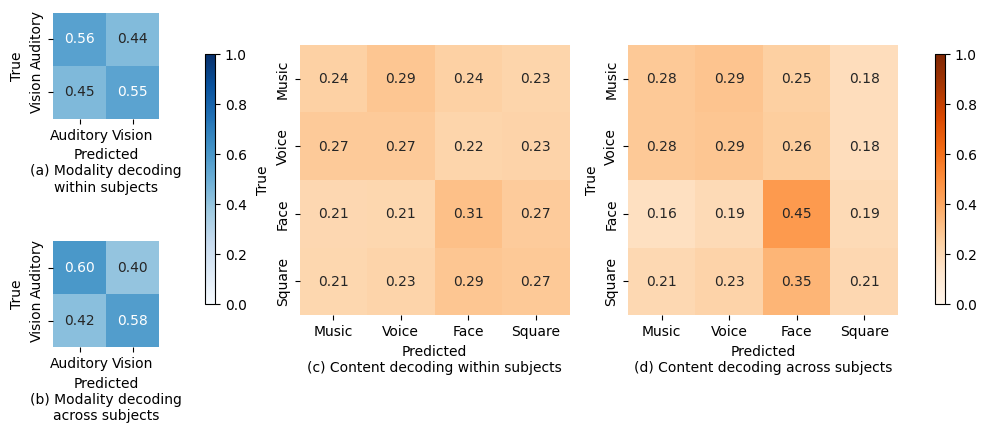

In [26]:
fig = plt.figure(figsize=(10, 5))
ax_2w = plt.subplot2grid((2, 12), (0, 0), colspan=2)          # 第一行第一列
ax_2c = plt.subplot2grid((2, 12), (1, 0), colspan=2)          # 第二行第一列
ax_4w = plt.subplot2grid((2, 12), (0, 3), colspan=4, rowspan=2)  # 第2-3列，两行
ax_4c = plt.subplot2grid((2, 12), (0, 7), colspan=4, rowspan=2)  # 第4-5列，两行
#bar1 = plt.subplot2grid((2, 12), (0, 2), rowspan=2)  # 第6列，两行
#bar2 = plt.subplot2grid((2, 12), (0, 11), rowspan=2)  # 第6列，两行
bar1 = fig.add_axes([0.21, 0.3, 0.01, 0.5])
bar2 = fig.add_axes([0.94, 0.3, 0.01, 0.5])

label2 = ['Auditory', 'Vision']
label4 = [ 'Music', 'Voice', 'Face', 'Square']
plot_confusion_matrix(ax_2w, cm_2.mean((0,1,2)), label2, '(a) Modality decoding\nwithin subjects', cmap='Blues')#,shrink=0.8)
hm1 = plot_confusion_matrix(ax_2c, cm_2_csub.mean((0,1)), label2, '(b) Modality decoding\nacross subjects', cmap='Blues')#,shrink=0.8)
plot_confusion_matrix(ax_4w, cm_4.mean((0,1,2)), label4, '(c) Content decoding within subjects', cmap='Oranges')#,shrink=0.9)
hm2 = plot_confusion_matrix(ax_4c, cm_4_csub.mean((0,1)), label4, '(d) Content decoding across subjects', cmap='Oranges')#,shrink=0.9)
#plot_confusion_matrix(ax_vc, cal_confusion_matrix(matrix["vc"]).mean(0), label2, 'VC', cmap='Oranges')#,shrink=0.8)
#plot_confusion_matrix(ax_ac, cal_confusion_matrix(matrix["ac"]).mean(0), label2, 'AC', cmap='Oranges')#,shrink=0.8)

fig.colorbar(hm1.collections[0],cax=bar1)
fig.colorbar(hm2.collections[0],cax=bar2)

plt.tight_layout()
plt.savefig("multi/fig/mi.pdf", bbox_inches="tight")
plt.show()
